In [1]:
#load class
import numpy as np
import pandas as pd # in case it's not installed then install using conda create -c conda-forge -n name_of_my_env python pandas
# more installations information can be found: https://pandas.pydata.org/docs/getting_started/install.html
import os
#load sklearn module for creating and evaluating ML models. In case sklearn isn't installed,
#follow this link https://scikit-learn.org/stable/install.html for further details on the installation process.
from sklearn.neighbors import KNeighborsClassifier #load your classifier. In this code, I have used KNN. You can choose other algorithms. You have to use at least 3 to complete this.
from sklearn.preprocessing import StandardScaler #module for perform scaling
from sklearn.model_selection import train_test_split #module for splitting datatset
from sklearn import metrics #module for evaluating performance

In [2]:
#load your data
df = pd.read_csv("data.csv") #change the name accordingly
df.head() # prints top 5 rows from the datatset to check data is load or not

,Temp,Humd,Label
0,23.0,53.0,1.0
1,23.0,53.0,1.0
2,23.0,53.0,1.0
3,23.0,53.0,1.0
4,23.0,53.0,1.0


In [3]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing Values:\n", missing_values)

Missing Values:
 Temp     0
Humd     0
Label    0
dtype: int64


In [4]:
# remove duplicatesd
df = df.drop_duplicates()

In [5]:
# prepare features
x = df.drop(['Label'],axis=1) #remove class or label
y = df['Label'] #load label

In [6]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.2) #split datatset. Here ratio is 80:20. Change accordingly

In [7]:
# Scale the data using standardization
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train) #scale training set
x_test = scaler.transform(x_test) #scale test set

In [8]:
z = KNeighborsClassifier(n_neighbors=3) # KNN classifier for 3 neighbours
KNN = z.fit(x_train,y_train) # start training
predict = KNN.predict(x_test) # performance in the test set

In [9]:
print("Accuracy:", metrics.accuracy_score(y_test,predict)) # evaluating the performance based on accuracy

Accuracy: 0.9090909090909091


In [19]:
import pickle
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC()
}

results = {}
for name, model in models.items():
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    acc = metrics.accuracy_score(y_test, pred)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")


    # save model
    filename = f"{name.replace(' ', '_')}.pkl"
    with open(filename, "wb") as file:
        pickle.dump(model, file)

KNN Accuracy: 0.9091
Decision Tree Accuracy: 0.9481
Random Forest Accuracy: 0.9654
SVM Accuracy: 0.8571


KNN Accuracy: 0.9091


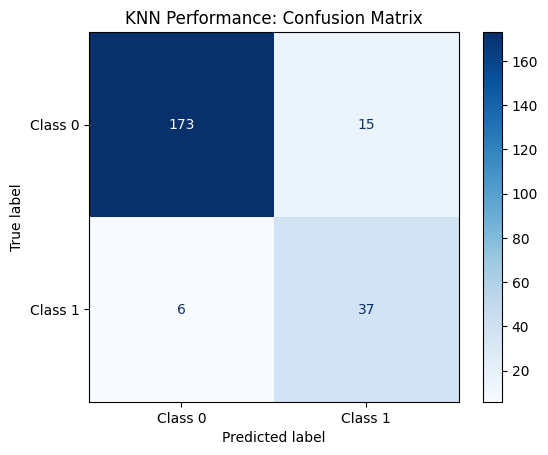

Decision Tree Accuracy: 0.9481


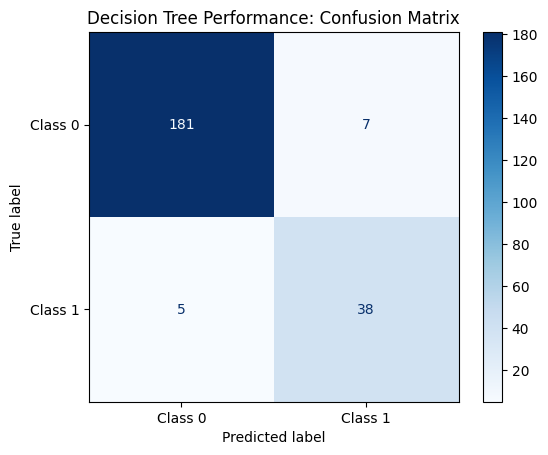

Random Forest Accuracy: 0.9654


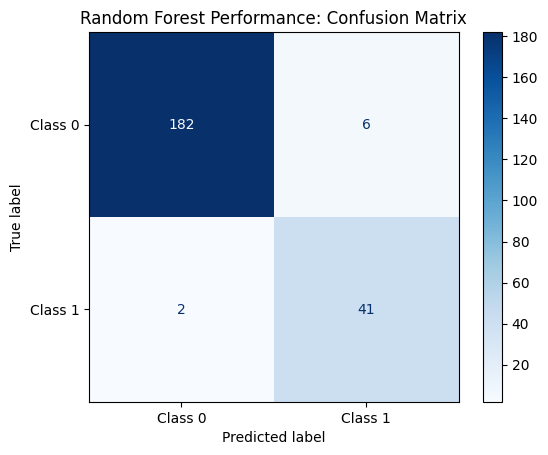

SVM Accuracy: 0.8571


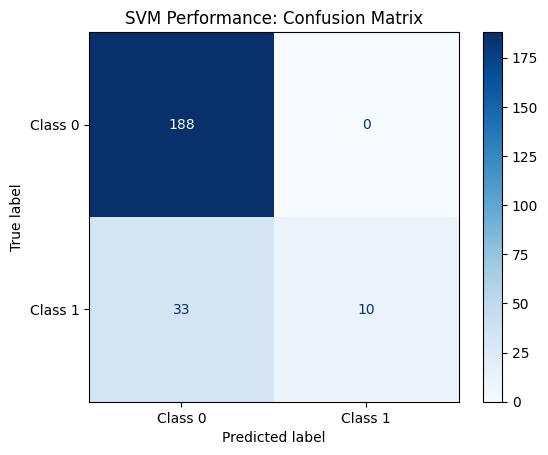

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


loaded_models = {}

for name, model in models.items():
    filename = f"{name.replace(' ', '_')}.pkl"
    with open (filename, 'rb') as file:
        model = pickle.load(file)
    loaded_models[name] = model
    pred = model.predict(x_test)
    acc = metrics.accuracy_score(y_test, pred)
    print(f"{name} Accuracy: {acc:.4f}")
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"{name} Performance: Confusion Matrix")
    plt.show()
